# Treino dos modelos

**Alvo:** `NU_NOTA_MT` (nota de Matemática). **Tarefa:** regressão. **Métrica principal:** RMSE (MAE e R² complementares), sempre na escala original, com média e desvio padrão nas 3 dobras.

**Protocolo:** 80% desenvolvimento / 20% teste (`random_state=42`); validação cruzada só no desenvolvimento, com `KFold(n_splits=3, shuffle=True, random_state=42)` e as mesmas dobras em tudo; tudo que é aprendido dos dados fica dentro de um `Pipeline`. O teste só é usado no final.

**Datasets** (em `dados/processed/`): `dataset_1_fundido`, `dataset_1_features`, `dataset_2_escola`, `dataset_2_features_escola` e as 4 tabelas do `dataset_3_*`. Cada modelo é treinado por dataset e os resultados são comparados no fim. Os modelos treinados são salvos em `models/`.

| Seção | Modelo |
|---|---|
| 0 | Preparação comum (dados, dobras, avaliação, salvar modelo) |
| 1 | Baseline pela média |
| 2 | Regressão linear (sem e com regularização) |
| 3 | Árvore de decisão |
| 4 | KNN (vizinhos mais próximos) |
| 5 | SVR (máquina de vetores de suporte) |
| 6 | Bagging |
| 7 | Pasting |
| 8 | Random Forest |
| 9 | Gradient Boosting |
| 10 | Stacking |
| 11 | Comparação dos modelos |

## 0. Preparação

Uma célula lê o dataset e fica **só com os 80% do desenvolvimento** (o teste não é aberto), separa `X` (as features) de `y` (a nota) e carrega as 3 dobras da validação cruzada que já estão salvas em `dados/splits/`. Para treinar em outro dataset, troque só a linha `NOME`.

In [54]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import PredefinedSplit, cross_val_predict, cross_validate

DATASETS = ["dataset_1_fundido", "dataset_1_features", "dataset_2_escola", "dataset_2_features_escola",
            "dataset_3_sem_escola", "dataset_3_sem_escola_features", "dataset_3_escola", "dataset_3_escola_features"]
NOME = "dataset_1_fundido"        # para treinar em outro dataset, troque só esta linha

# quem está no desenvolvimento (80%) e a dobra (1, 2 ou 3) de cada pessoa: arquivos salvos em dados/splits/
ids = pd.read_csv("../dados/processed/ids_elegiveis.csv")["NU_INSCRICAO"]
em_desenvolvimento = ids.isin(pd.read_csv("../dados/splits/desenvolvimento_ids.csv")["NU_INSCRICAO"]).to_numpy()
dobras = PredefinedSplit(pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy())


def carregar(nome):
    """Lê o dataset e devolve só o desenvolvimento: X (features) e y (nota de Matemática). O teste não é carregado."""
    dev = pd.read_csv(f"../dados/processed/{nome}.csv")[em_desenvolvimento]
    return dev.drop(columns="NU_NOTA_MT"), dev["NU_NOTA_MT"]


X, y = carregar(NOME)
amostra = np.random.default_rng(42).choice(len(y), 20_000, replace=False)   # 20 mil pessoas sorteadas, só para desenhar gráficos
resultados = {}                                                             # aqui ficam as métricas de cada modelo, para a comparação final
print(f"{NOME}: {X.shape[0]:,} pessoas no desenvolvimento, {X.shape[1]} features")

dataset_1_fundido: 2,153,941 pessoas no desenvolvimento, 30 features


A função `avaliar` mede um modelo: ele treina em 2 dobras, é testado na terceira, três vezes, e ela devolve a **média** e o **desvio** de cada métrica. Se você passar um nome, o resultado também vai para `resultados`.

- **RMSE:** o erro típico em pontos de nota (pune mais os erros grandes). É a métrica principal.
- **MAE:** o erro médio em pontos, sem sinal.
- **R²:** quanto da variação da nota o modelo explica (0 = nada além da média, 1 = tudo).
- **MSE:** o erro ao quadrado médio; o RMSE é a raiz dele.
- **tempo_s:** segundos para treinar e prever em uma dobra.

In [55]:
def avaliar(modelo, nome=None):
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error",
                "R2": "r2", "MSE": "neg_mean_squared_error"}      # o scikit-learn devolve os erros com sinal negativo
    r = cross_validate(modelo, X, y, cv=dobras, scoring=metricas)
    por_dobra = pd.DataFrame({"RMSE": -r["test_RMSE"], "MAE": -r["test_MAE"], "R2": r["test_R2"], "MSE": -r["test_MSE"],
                              "tempo_s": r["fit_time"] + r["score_time"]})
    resumo = pd.DataFrame({"média": por_dobra.mean(), "desvio": por_dobra.std()})
    if nome:
        resultados[nome] = resumo
    return resumo.round(3)

Três funções de apoio para os modelos que demoram. Elas treinam **na dobra 1** (não repetem a validação cruzada inteira):

- `real_x_previsto`: desenha 20 mil pessoas da validação, nota real contra nota prevista.
- `importancia_por_permutacao`: embaralha uma coluna da validação e mede **quanto o RMSE sobe**; quanto mais sobe, mais o modelo dependia daquela feature. Serve para qualquer modelo.
- `grafico_importancia`: desenha as 15 maiores.

In [56]:
from sklearn.inspection import permutation_importance


def treinar_dobra1(modelo):
    treino, validacao = next(iter(dobras.split()))
    return clone(modelo).fit(X.iloc[treino], y.iloc[treino]), validacao


def real_x_previsto(modelo, titulo):
    m, validacao = treinar_dobra1(modelo)
    sorteio = np.random.default_rng(42).choice(validacao, min(20_000, len(validacao)), replace=False)
    plt.figure(figsize=(6, 5))
    plt.scatter(y.iloc[sorteio], m.predict(X.iloc[sorteio]), s=3, alpha=0.1)
    plt.plot([0, 1000], [0, 1000], color="green", label="previsão perfeita")
    plt.title(f"Nota real x nota prevista ({titulo})")
    plt.xlabel("nota real")
    plt.ylabel("nota prevista")
    plt.legend()
    plt.show()


def importancia_por_permutacao(modelo, n_linhas=5000, repeticoes=3):
    m, validacao = treinar_dobra1(modelo)
    sorteio = np.random.default_rng(42).choice(validacao, min(n_linhas, len(validacao)), replace=False)
    r = permutation_importance(m, X.iloc[sorteio], y.iloc[sorteio], scoring="neg_root_mean_squared_error",
                               n_repeats=repeticoes, random_state=42)
    return pd.Series(r.importances_mean, index=X.columns).sort_values()


def grafico_importancia(serie, titulo, xlabel):
    top = serie.tail(15)
    plt.figure(figsize=(7, 5))
    plt.barh(top.index, top.values)
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.show()

## 1. Baseline pela média

**O que é:** `DummyRegressor(strategy="mean")`: aprende a média da nota no treino e prevê esse mesmo valor para todos, sem usar nenhuma feature.

**Pontos de atenção:** É a referência do erro: qualquer modelo útil precisa ficar abaixo do RMSE dele. A média é recalculada no treino de cada dobra (e, no teste final, nos 80% de desenvolvimento), nunca com o teste. Não tem hiperparâmetros.

### Passo 1: treinar e medir

O `DummyRegressor` aprende só a média da nota do treino e prevê esse valor para todo mundo. Qualquer modelo útil precisa ter RMSE **menor** que o dele e R² **maior que 0**.

In [57]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")      # prevê sempre a média da nota do treino
avaliar(baseline, "Baseline")

,média,desvio
RMSE,131.634,0.158
MAE,107.582,0.058
R2,-0.000,0.000
MSE,17327.557,41.542
tempo_s,0.059,0.037


### Passo 2: gráficos

À esquerda, como a nota se distribui. À direita, **cada ponto é uma pessoa**: nota real (horizontal) contra nota prevista (vertical). A reta verde é a previsão perfeita. O baseline prevê sempre o mesmo valor, então os pontos ficam numa linha horizontal.

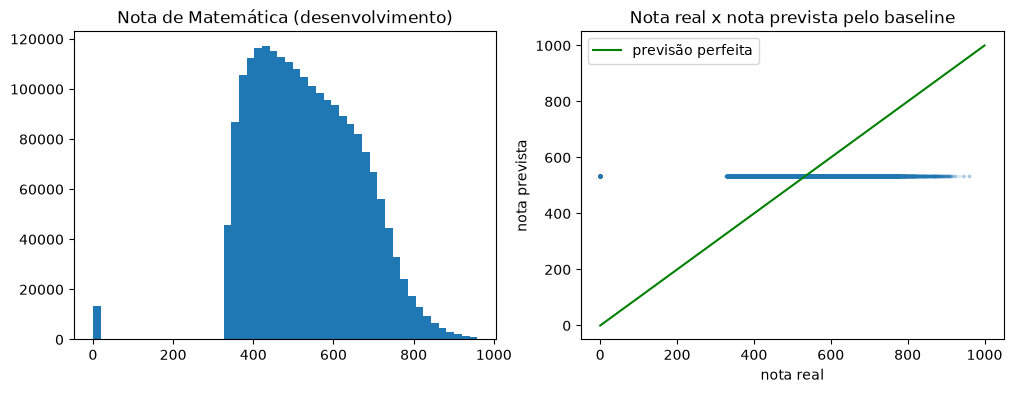

In [58]:
previsto = cross_val_predict(baseline, X, y, cv=dobras)      # previsão de cada pessoa, feita sem ela no treino

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y, bins=50)
ax[0].set_title("Nota de Matemática (desenvolvimento)")
ax[1].scatter(y.iloc[amostra], previsto[amostra], s=3, alpha=0.1)
ax[1].plot([0, 1000], [0, 1000], color="green", label="previsão perfeita")
ax[1].set_title("Nota real x nota prevista pelo baseline")
ax[1].set_xlabel("nota real")
ax[1].set_ylabel("nota prevista")
ax[1].legend()
plt.show()

### Passo 3: treinar nos 80% e salvar em `models/`

In [59]:
baseline.fit(X, y)                                              # treina nos 80% inteiros
joblib.dump(baseline, f"../models/baseline_{NOME}.joblib")      # salva em models/

['../models/baseline_dataset_1_fundido.joblib']

## 2. Regressão linear (sem e com regularização)

**O que é:** `LinearRegression` (sem regularização) e `Ridge` ou `Lasso` (com regularização): a nota é uma soma ponderada das features. A regularização encolhe os pesos para a conta não ficar instável quando as colunas se parecem.

**Pontos de atenção:** O PDF pede as duas versões. Precisa de `StandardScaler` dentro do Pipeline. A regressão sem regularização também é reajustada nos 80% e avaliada no teste final. Hiperparâmetro: `alpha`.

### Passo 1: regressão linear

Calcula a nota como uma soma ponderada das features (`b0 + b1·Q006 + b2·Q024 + ...`). O `StandardScaler` coloca todas as colunas na mesma escala antes disso. O `make_pipeline` junta os dois passos numa receita só, e na validação cruzada a padronização é refeita só com o treino de cada dobra.

In [60]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

regressao_linear = make_pipeline(StandardScaler(), LinearRegression())     # 1) padroniza as colunas  2) regressão linear
avaliar(regressao_linear, "Regressão linear")

,média,desvio
RMSE,111.153,0.178
MAE,86.960,0.059
R2,0.287,0.001
MSE,12354.950,39.569
tempo_s,0.678,0.094


### Passo 2: Ridge e comparação

O Ridge é a mesma conta com um freio nos pesos (`alpha`). Aqui usamos o valor inicial 1,0. Tabela com os modelos até agora, nas mesmas dobras: Ridge e regressão linear saem iguais, porque o freio quase não pesa com 2 milhões de linhas.

In [61]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))                  # igual, mas com regularização (alpha = força do freio)
avaliar(ridge, "Ridge")
pd.DataFrame({nome: r["média"] for nome, r in resultados.items()}).T[["RMSE", "MAE", "R2", "MSE", "tempo_s"]].round(3)

,RMSE,MAE,R2,MSE,tempo_s
Baseline,131.634,107.582,-0.000,17327.557,0.059
Regressão linear,111.153,86.960,0.287,12354.950,0.678
Ridge,111.153,86.960,0.287,12354.950,0.300


### Passo 3: as features que mais influenciaram

Na regressão linear, o **peso de cada feature** diz isso: quantos pontos a nota muda quando a feature sobe 1 desvio padrão, com as outras fixas. Barra azul sobe a nota, barra vermelha desce. É associação nos dados, não causa.

Intercepto: 533.8  (a nota média)


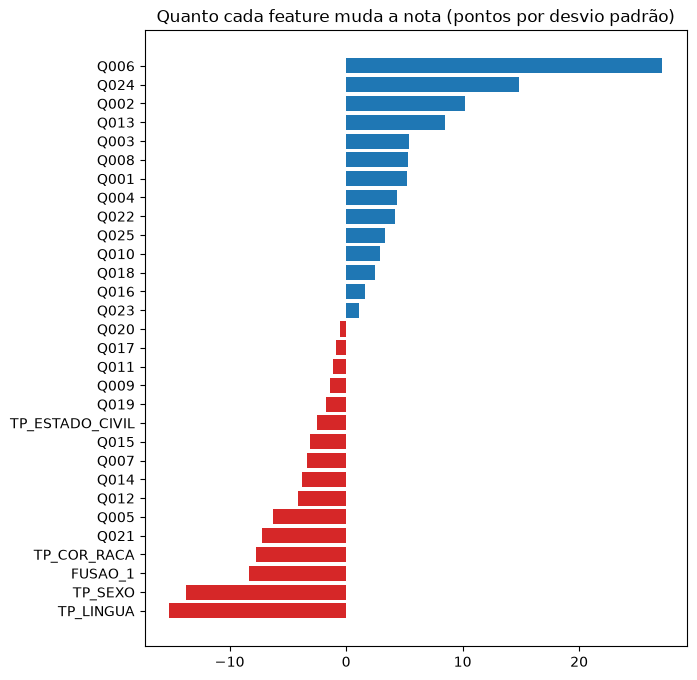

In [62]:
regressao_linear.fit(X, y)
pesos = pd.Series(regressao_linear[-1].coef_, index=X.columns).sort_values()     # um peso por feature

print(f"Intercepto: {regressao_linear[-1].intercept_:.1f}  (a nota média)")
plt.figure(figsize=(7, 8))
plt.barh(pesos.index, pesos.values, color=["tab:red" if v < 0 else "tab:blue" for v in pesos.values])
plt.title("Quanto cada feature muda a nota (pontos por desvio padrão)")
plt.show()

### Passo 4: nota real × nota prevista

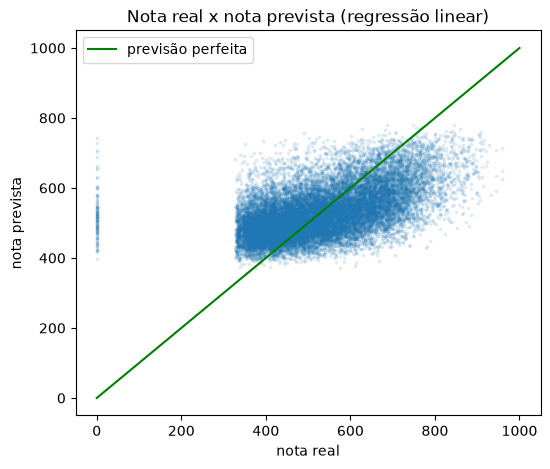

In [63]:
previsto = cross_val_predict(regressao_linear, X, y, cv=dobras)

plt.figure(figsize=(6, 5))
plt.scatter(y.iloc[amostra], previsto[amostra], s=3, alpha=0.1)
plt.plot([0, 1000], [0, 1000], color="green", label="previsão perfeita")
plt.title("Nota real x nota prevista (regressão linear)")
plt.xlabel("nota real")
plt.ylabel("nota prevista")
plt.legend()
plt.show()

### Passo 5: salvar em `models/`

In [64]:
for nome_modelo, modelo in {"regressao_linear": regressao_linear, "ridge": ridge}.items():
    modelo.fit(X, y)
    joblib.dump(modelo, f"../models/{nome_modelo}_{NOME}.joblib")

## 3. Árvore de decisão

**O que é:** `DecisionTreeRegressor`: divide os participantes em grupos por perguntas do tipo "`Q006` > 5?" e prevê a média da nota de cada grupo.

**Pontos de atenção:** Não precisa padronizar e aproveita relações que não são em linha reta. Sozinha tende a decorar o treino, então a profundidade precisa ser limitada. Hiperparâmetros: `max_depth`, `min_samples_leaf`, `min_samples_split`.

### Passo 1: treinar e medir

A árvore faz perguntas sobre as features e agrupa as pessoas parecidas; a previsão de cada grupo é a **média da nota** de quem caiu nele. Ela **não precisa do `StandardScaler`**, porque só compara cada feature com um limite ("`Q006` ≤ 4?"), e a escala não muda a resposta.

Configuração inicial, antes de qualquer busca: `max_depth=10` (no máximo 10 perguntas em sequência) e `min_samples_leaf=50` (cada grupo final tem pelo menos 50 pessoas).

In [65]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

# configuração inicial (antes de qualquer busca): árvore com no máximo 10 níveis e pelo menos 50 pessoas em cada folha
arvore = DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=42)
avaliar(arvore, "Árvore de decisão")

,média,desvio
RMSE,110.551,0.190
MAE,86.381,0.076
R2,0.295,0.001
MSE,12221.635,42.011
tempo_s,2.973,0.156


### Passo 2: como a árvore "pensa"

Uma árvore pequena, de só 3 níveis, para enxergar. Cada caixa faz uma pergunta (`Q006 <= 4.0` é "a renda é de até a faixa E?"). Quem responde sim vai para a esquerda, quem responde não vai para a direita. Em cada caixa, `samples` é quantas pessoas chegaram ali e `value` é a nota média delas. Quanto mais escura a caixa, maior a nota.

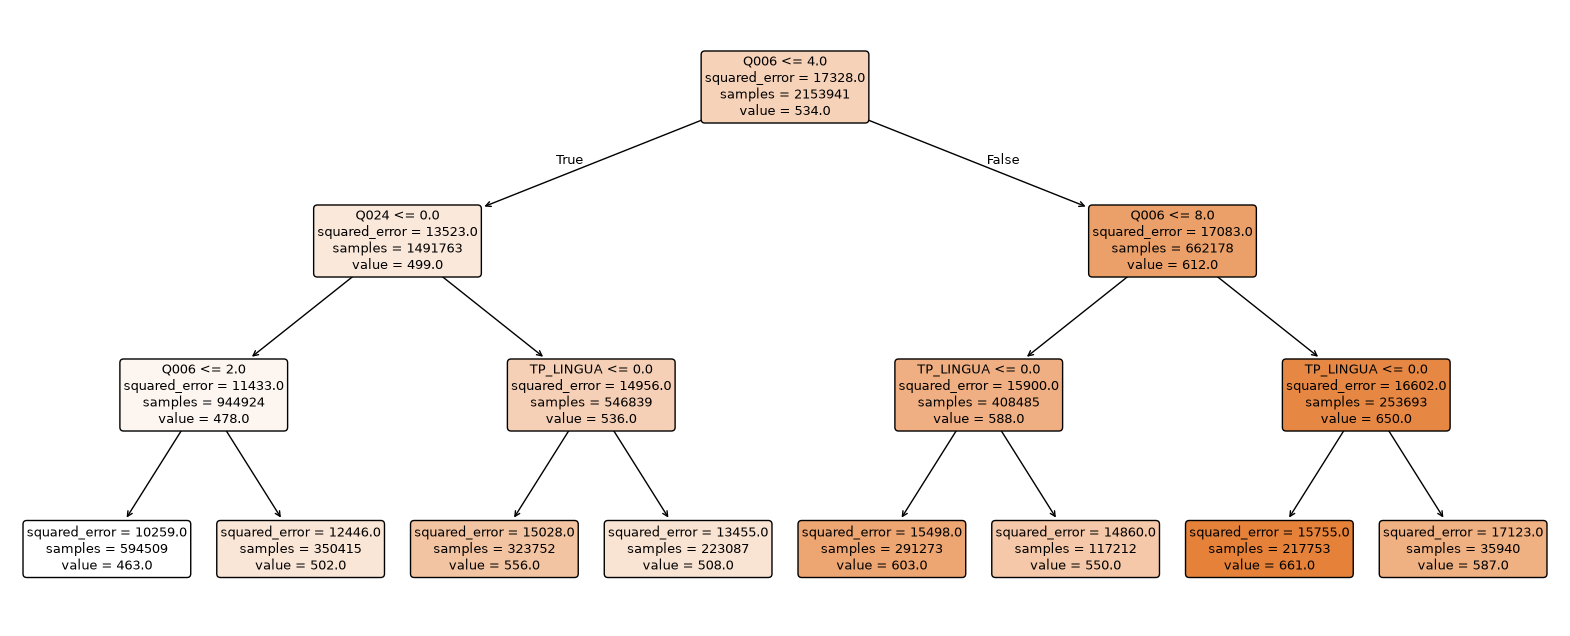

In [66]:
pequena = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X, y)

plt.figure(figsize=(20, 8))
plot_tree(pequena, feature_names=list(X.columns), filled=True, rounded=True, fontsize=9, precision=0)
plt.show()

### Passo 3: por que limitar a profundidade

Com mais níveis a árvore faz mais perguntas e se ajusta melhor ao treino. Mas passa um ponto em que ela só decora os casos do treino e **piora em quem ela não viu**. O gráfico compara o erro no treino e o erro na validação para várias profundidades (em uma dobra só). Quando as duas linhas se afastam, é **overfitting**.

              RMSE no treino  RMSE na validação
profundidade                                   
2                     117.44             117.33
4                     114.09             113.97
6                     112.20             112.05
10                    110.13             110.45
15                    107.99             110.72
25                    106.56             111.57


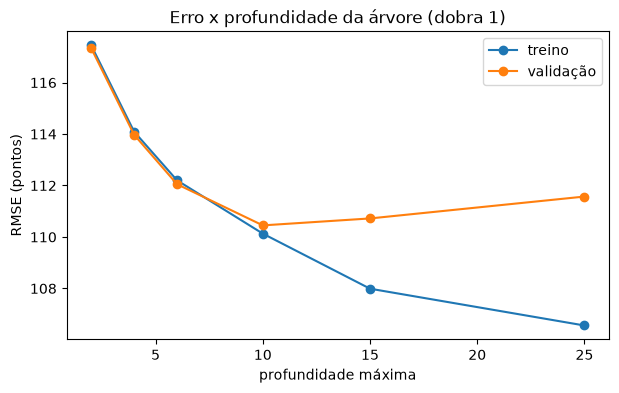

In [67]:
from sklearn.metrics import root_mean_squared_error

treino, validacao = next(iter(dobras.split()))
linhas = []
for prof in [2, 4, 6, 10, 15, 25]:
    m = DecisionTreeRegressor(max_depth=prof, min_samples_leaf=50, random_state=42).fit(X.iloc[treino], y.iloc[treino])
    linhas.append({"profundidade": prof,
                   "RMSE no treino": root_mean_squared_error(y.iloc[treino], m.predict(X.iloc[treino])),
                   "RMSE na validação": root_mean_squared_error(y.iloc[validacao], m.predict(X.iloc[validacao]))})
curva = pd.DataFrame(linhas).set_index("profundidade").round(2)
print(curva)

plt.figure(figsize=(7, 4))
plt.plot(curva.index, curva["RMSE no treino"], marker="o", label="treino")
plt.plot(curva.index, curva["RMSE na validação"], marker="o", label="validação")
plt.title("Erro x profundidade da árvore (dobra 1)")
plt.xlabel("profundidade máxima")
plt.ylabel("RMSE (pontos)")
plt.legend()
plt.show()

### Passo 4: as features que mais influenciaram

A `feature_importances_` da árvore diz quanto cada feature reduziu o erro nas divisões; a soma de todas é 1. É diferente do peso da regressão linear: aqui não tem sinal (não diz se sobe ou desce a nota), só o quanto a feature ajudou a separar as pessoas.

Q003         0.027
TP_SEXO      0.037
FUSAO_1      0.048
TP_LINGUA    0.078
Q024         0.118
Q006         0.622


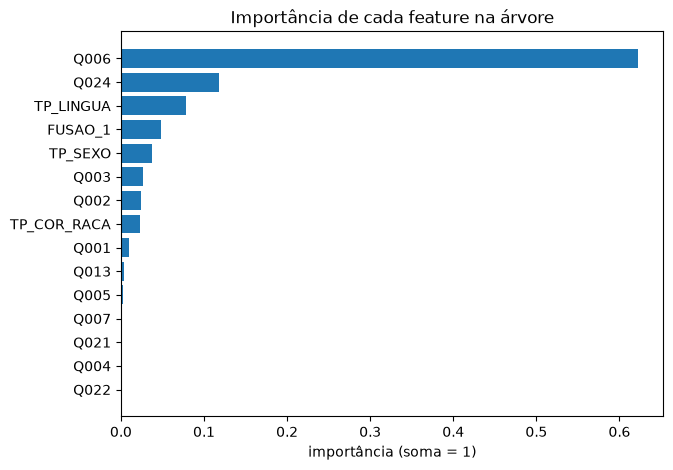

In [68]:
arvore.fit(X, y)
importancia = pd.Series(arvore.feature_importances_, index=X.columns).sort_values()     # soma 1; quanto maior, mais a feature reduz o erro
print(importancia.tail(6).round(3).to_string())
grafico_importancia(importancia, "Importância de cada feature na árvore", "importância (soma = 1)")

### Passo 5: nota real × nota prevista

Como a árvore prevê a média de cada grupo, as previsões formam **faixas horizontais**: há poucos valores diferentes de previsão (um por folha).

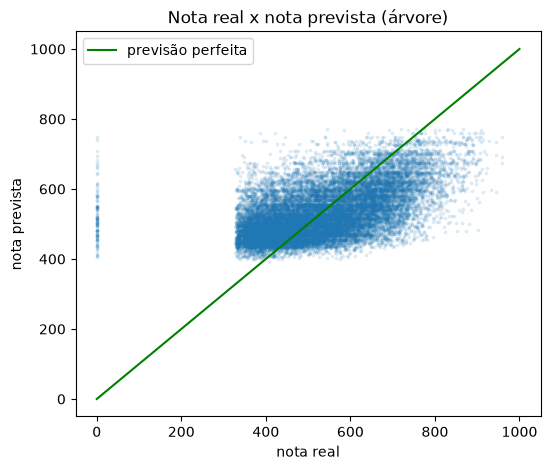

In [69]:
previsto = cross_val_predict(arvore, X, y, cv=dobras)

plt.figure(figsize=(6, 5))
plt.scatter(y.iloc[amostra], previsto[amostra], s=3, alpha=0.1)
plt.plot([0, 1000], [0, 1000], color="green", label="previsão perfeita")
plt.title("Nota real x nota prevista (árvore)")
plt.xlabel("nota real")
plt.ylabel("nota prevista")
plt.legend()
plt.show()

### Passo 6: salvar em `models/`

In [70]:
arvore.fit(X, y)
joblib.dump(arvore, f"../models/arvore_decisao_{NOME}.joblib")

['../models/arvore_decisao_dataset_1_fundido.joblib']

## 4. KNN (vizinhos mais próximos)

**O que é:** `KNeighborsRegressor`: para cada participante, acha os k mais parecidos no treino e prevê a média da nota deles.

**Pontos de atenção:** Precisa de `StandardScaler` dentro do Pipeline (usa distância). Com mais de 2 milhões de linhas a previsão é lenta, então é preciso planejar tempo e memória e registrar os limites. Hiperparâmetros: `n_neighbors`, `weights`, `p`.

### Passo 1: treinar e medir

Para cada pessoa, o KNN acha as 50 mais parecidas no treino (distância entre as features já padronizadas) e prevê a **média da nota delas**. Não há "aprendizado": o treino só guarda os dados, e todo o trabalho acontece na hora de prever. Por isso o `StandardScaler` é obrigatório (sem ele, `Q005` de 1 a 20 pesaria mais que `TP_SEXO` de 0 a 1).

Configuração inicial: 50 vizinhos, todos com o mesmo peso. `algorithm="brute"` compara com todo o treino; com 30 colunas foi bem mais rápido que as árvores de busca do scikit-learn.

**Atenção ao tempo:** cada previsão compara com cerca de 1,4 milhão de pessoas. Medimos cerca de 6 minutos por dobra, então a validação cruzada leva **cerca de 20 minutos**.

In [71]:
from sklearn.neighbors import KNeighborsRegressor

knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50, algorithm="brute", n_jobs=-1))
avaliar(knn, "KNN")

,média,desvio
RMSE,111.575,0.184
MAE,87.180,0.080
R2,0.282,0.001
MSE,12449.014,41.104
tempo_s,476.276,41.006


### Passo 2: as features que mais influenciaram

O KNN não tem pesos nem importâncias prontas. Usamos a importância por permutação, **numa amostra de 3.000 pessoas da validação da dobra 1**, porque cada previsão é cara.

TP_COR_RACA    0.95
Q006           0.96
FUSAO_1        1.31
Q024           1.66
TP_LINGUA      2.18
TP_SEXO        2.58


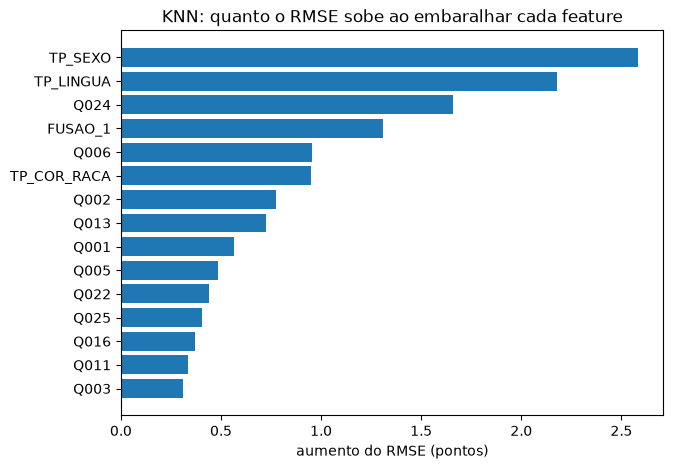

In [72]:
imp_knn = importancia_por_permutacao(knn, n_linhas=3000, repeticoes=2)
print(imp_knn.tail(6).round(2).to_string())
grafico_importancia(imp_knn, "KNN: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista

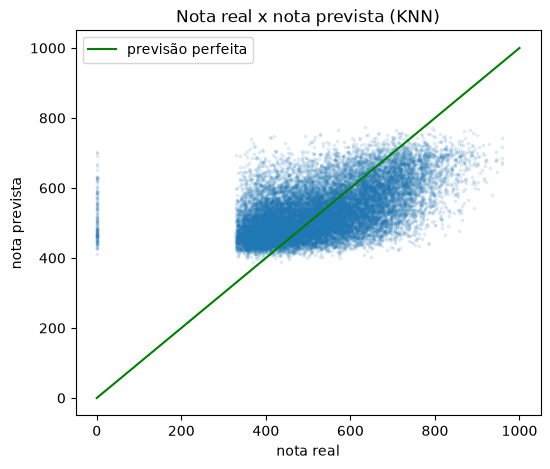

In [73]:
real_x_previsto(knn, "KNN")

### Passo 4: salvar em `models/`

O KNN guarda **todo o treino** dentro do modelo, então o arquivo é grande (cerca de meio gigabyte).

In [74]:
knn.fit(X, y)
joblib.dump(knn, f"../models/knn_{NOME}.joblib")

['../models/knn_dataset_1_fundido.joblib']

## 5. SVR (máquina de vetores de suporte)

**O que é:** `SVR`: ajusta uma curva que tenta errar no máximo `epsilon` para a maioria dos pontos e só penaliza quem passa disso. O kernel (linear, RBF, polinomial) define o formato da curva.

**Pontos de atenção:** O PDF pede justificar o kernel; `LinearSVR` também é permitido. O SVR com kernel é muito pesado com milhões de linhas, então vale registrar o tempo e, se preciso, usar o `LinearSVR`. Precisa de `StandardScaler`. Hiperparâmetros: `kernel`, `C`, `epsilon`, `gamma`.

### Passo 1: por que não dá para usar o SVR com kernel

O SVR com kernel (RBF, polinomial) compara **todos os pares de pessoas**: o tempo cresce com o quadrado do número de linhas. Medimos com amostras pequenas e estimamos para o treino de uma dobra (cerca de 1,4 milhão de pessoas). É só um diagnóstico de custo; **não substitui a base**.

In [75]:
import time
from sklearn.svm import SVR

dados_treino, _ = next(iter(dobras.split()))
tempos = []
for n in [2_000, 4_000, 8_000]:
    sorteio = np.random.default_rng(42).choice(dados_treino, n, replace=False)
    t0 = time.time()
    make_pipeline(StandardScaler(), SVR(kernel="rbf")).fit(X.iloc[sorteio], y.iloc[sorteio])
    tempos.append((n, time.time() - t0))
    print(f"SVR RBF com {n:>6,} pessoas: {tempos[-1][1]:5.1f} s")

n_cheio = len(dados_treino)
estimativa_h = tempos[-1][1] * (n_cheio / tempos[-1][0]) ** 2 / 3600
print(f"\nO tempo cresce ~{tempos[-1][1] / tempos[-2][1]:.1f}x ao dobrar as pessoas (quadrático seria 4x).")
print(f"Estimativa para {n_cheio:,} pessoas em UMA dobra: ~{estimativa_h:,.0f} horas.")

SVR RBF com  2,000 pessoas:   0.1 s
SVR RBF com  4,000 pessoas:   0.2 s
SVR RBF com  8,000 pessoas:   1.0 s

O tempo cresce ~4.0x ao dobrar as pessoas (quadrático seria 4x).
Estimativa para 1,435,960 pessoas em UMA dobra: ~9 horas.


### Passo 2: SVR linear (`LinearSVR`)

O PDF permite o `LinearSVR`, que usa kernel linear e é bem mais rápido. Ele tenta errar no máximo `epsilon` (aqui 0) e pune o erro ao quadrado, com o freio `C`. Precisa de `StandardScaler`. Configuração inicial: `C=1.0`, `epsilon=0.0`.

**Justificativa do kernel:** o kernel linear é o único viável com 2 milhões de linhas, e dá um modelo parecido com a regressão linear.

In [76]:
from sklearn.svm import LinearSVR

svr = make_pipeline(StandardScaler(), LinearSVR(C=1.0, epsilon=0.0, loss="squared_epsilon_insensitive",
                                                 dual=False, max_iter=5000, random_state=42))
avaliar(svr, "SVR linear")

,média,desvio
RMSE,111.153,0.178
MAE,86.961,0.059
R2,0.287,0.001
MSE,12354.951,39.581
tempo_s,1.942,0.489


### Passo 3: as features que mais influenciaram

Como o kernel é linear, os **pesos** (`coef_`) dizem isso, como na regressão linear (pontos por desvio padrão da feature).

Q003     5.43
Q013     8.46
Q002    10.22
Q024    14.82
Q006    27.13


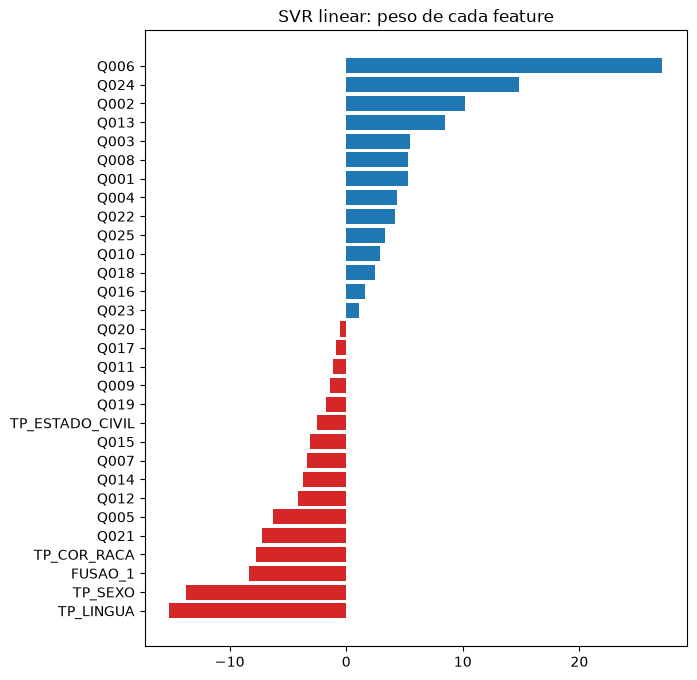

In [77]:
svr.fit(X, y)
pesos_svr = pd.Series(svr[-1].coef_, index=X.columns).sort_values()
print(pesos_svr.tail(5).round(2).to_string())
plt.figure(figsize=(7, 8))
plt.barh(pesos_svr.index, pesos_svr.values, color=["tab:red" if v < 0 else "tab:blue" for v in pesos_svr.values])
plt.title("SVR linear: peso de cada feature")
plt.show()

### Passo 4: nota real × nota prevista

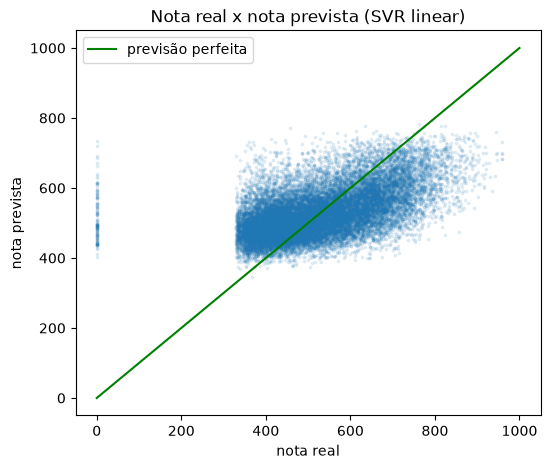

In [78]:
real_x_previsto(svr, "SVR linear")

### Passo 5: salvar em `models/`

In [79]:
joblib.dump(svr, f"../models/svr_linear_{NOME}.joblib")

['../models/svr_linear_dataset_1_fundido.joblib']

## 6. Bagging

**O que é:** `BaggingRegressor(bootstrap=True)`: treina vários modelos iguais, cada um numa amostra sorteada **com reposição**, e prevê a média deles.

**Pontos de atenção:** Reduz a variância de modelos instáveis, como a árvore. As subamostras são um mecanismo do algoritmo e não substituem a base nacional por um recorte. Hiperparâmetros: `n_estimators`, `max_samples`, `max_features`, modelo base.

### Passo 1: treinar e medir

O bagging treina **20 árvores**, cada uma numa amostra sorteada **com reposição** do treino (do mesmo tamanho do treino: algumas pessoas se repetem e outras ficam de fora). A previsão é a **média das 20 árvores**. Isso reduz a variância: cada árvore erra de um jeito, e a média compensa. A árvore base é a mesma da seção 3 (`max_depth=10`, `min_samples_leaf=50`).

Configuração inicial: `n_estimators=20`, `bootstrap=True`.

In [80]:
from sklearn.ensemble import BaggingRegressor

bagging = BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=10, min_samples_leaf=50),
                           n_estimators=20, bootstrap=True, n_jobs=-1, random_state=42)
avaliar(bagging, "Bagging")

,média,desvio
RMSE,110.014,0.207
MAE,85.991,0.090
R2,0.302,0.001
MSE,12103.132,45.624
tempo_s,24.135,0.522


### Passo 2: as features que mais influenciaram

Importância por permutação (quanto o RMSE sobe ao embaralhar a feature), na validação da dobra 1.

TP_COR_RACA    0.99
TP_SEXO        1.85
Q024           2.00
TP_LINGUA      2.73
FUSAO_1        2.78
Q006           8.19


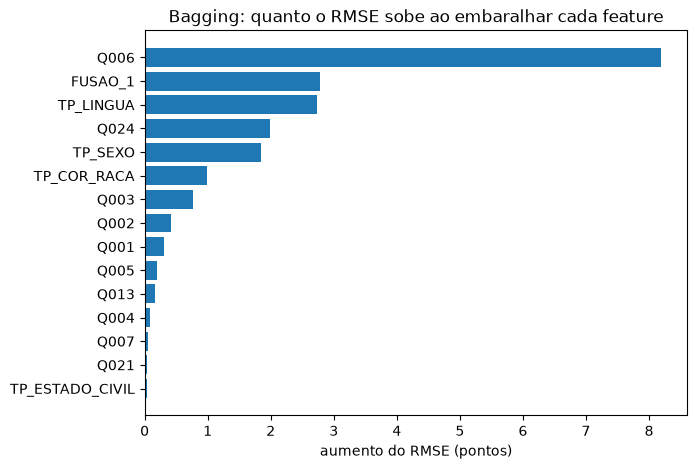

In [81]:
imp_bag = importancia_por_permutacao(bagging)
print(imp_bag.tail(6).round(2).to_string())
grafico_importancia(imp_bag, "Bagging: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista

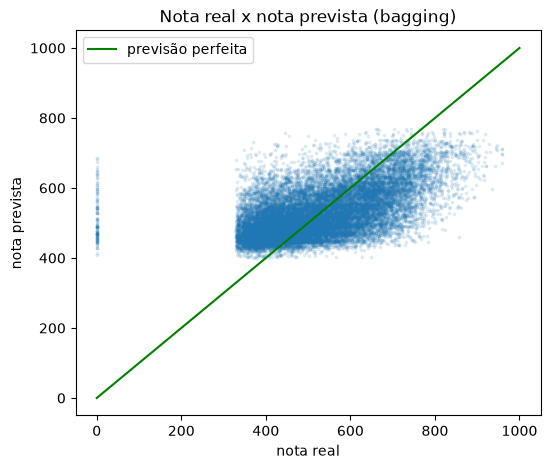

In [82]:
real_x_previsto(bagging, "bagging")

### Passo 4: salvar em `models/`

In [83]:
bagging.fit(X, y)
joblib.dump(bagging, f"../models/bagging_{NOME}.joblib")

['../models/bagging_dataset_1_fundido.joblib']

## 7. Pasting

**O que é:** `BaggingRegressor(bootstrap=False)` com `max_samples` menor que 1: igual ao bagging, mas cada subamostra é sorteada **sem reposição**.

**Pontos de atenção:** É a segunda forma de combinar modelos que o PDF pede; comparar com o bagging mostra o efeito da reposição. Hiperparâmetros: `n_estimators`, `max_samples`, `max_features`, modelo base.

### Passo 1: treinar e medir

O pasting é igual ao bagging, mas cada árvore recebe uma amostra sorteada **sem reposição**, e menor que o treino. Aqui, **metade do treino** (`max_samples=0.5`) para cada árvore. A única diferença para a seção anterior é `bootstrap=False` (e o tamanho da amostra), então comparar os dois mostra o efeito de sortear com ou sem reposição.

Configuração inicial: `n_estimators=20`, `bootstrap=False`, `max_samples=0.5`.

In [84]:
pasting = BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=10, min_samples_leaf=50),
                           n_estimators=20, bootstrap=False, max_samples=0.5, n_jobs=-1, random_state=42)
avaliar(pasting, "Pasting")

,média,desvio
RMSE,110.012,0.208
MAE,85.996,0.089
R2,0.302,0.001
MSE,12102.686,45.818
tempo_s,19.845,1.145


### Passo 2: as features que mais influenciaram

TP_COR_RACA    1.02
TP_SEXO        1.85
Q024           2.05
TP_LINGUA      2.75
FUSAO_1        2.77
Q006           8.34


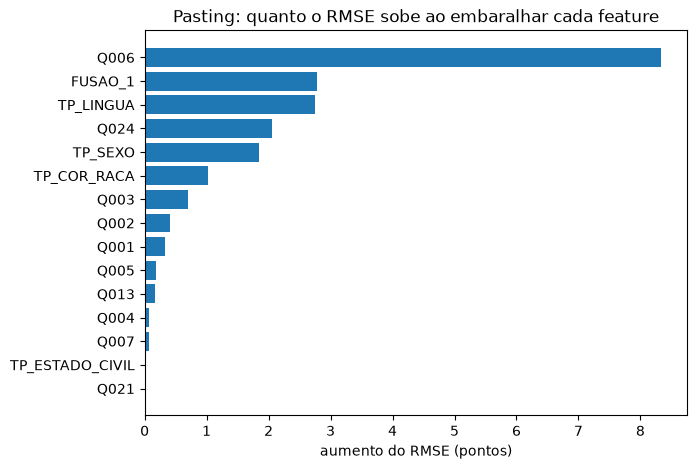

In [85]:
imp_past = importancia_por_permutacao(pasting)
print(imp_past.tail(6).round(2).to_string())
grafico_importancia(imp_past, "Pasting: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista

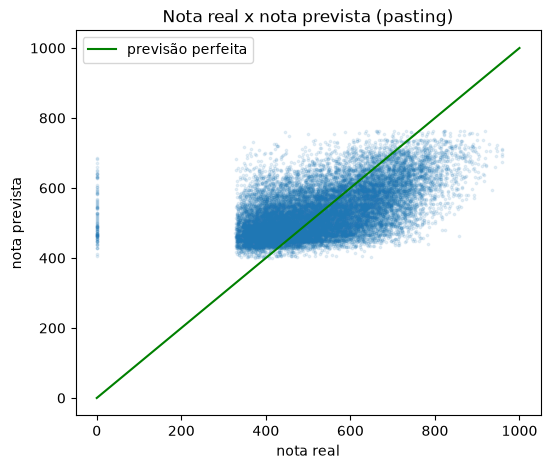

In [86]:
real_x_previsto(pasting, "pasting")

### Passo 4: salvar em `models/`

In [87]:
pasting.fit(X, y)
joblib.dump(pasting, f"../models/pasting_{NOME}.joblib")

['../models/pasting_dataset_1_fundido.joblib']

## 8. Random Forest

**O que é:** `RandomForestRegressor`: várias árvores, cada uma numa amostra e escolhendo entre um sorteio de colunas a cada divisão; a previsão é a média das árvores.

**Pontos de atenção:** É um bagging de árvores com sorteio de colunas, em geral bem mais forte que uma árvore só. Com 2 milhões de linhas, limitar `n_estimators` e `max_depth`. Hiperparâmetros: `n_estimators`, `max_depth`, `max_features`, `min_samples_leaf`.

### Passo 1: treinar e medir

A Random Forest é um bagging de árvores com um truque a mais: em cada divisão, cada árvore só pode escolher entre **uma parte sorteada das features** (`max_features=0.5`, metade). Isso faz as árvores serem diferentes entre si, e a média delas erra menos.

Configuração inicial: `n_estimators=100`, `max_depth=12`, `min_samples_leaf=50`, `max_features=0.5`.

In [88]:
from sklearn.ensemble import RandomForestRegressor

floresta = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=50, max_features=0.5,
                                 n_jobs=-1, random_state=42)
avaliar(floresta, "Random Forest")

,média,desvio
RMSE,109.422,0.195
MAE,85.494,0.086
R2,0.309,0.001
MSE,11973.271,42.641
tempo_s,103.420,7.265


### Passo 2: as features que mais influenciaram

A floresta tem `feature_importances_` (a média das importâncias das árvores, soma 1). Para conferir, também a importância por permutação.

TP_SEXO      0.038
FUSAO_1      0.050
Q003         0.079
TP_LINGUA    0.079
Q024         0.190
Q006         0.420


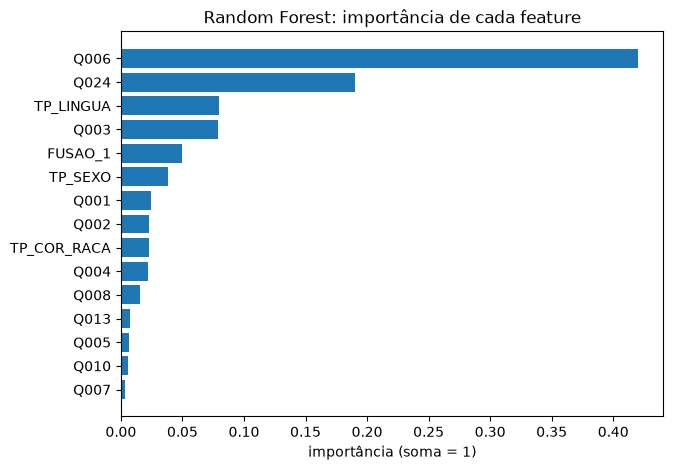

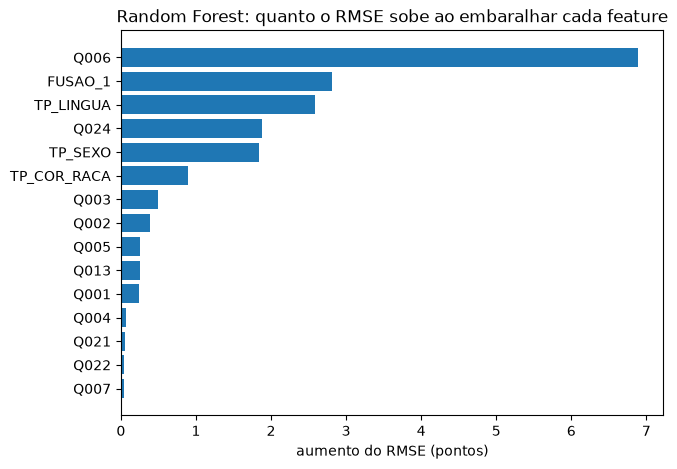

In [89]:
floresta.fit(X, y)
imp_rf = pd.Series(floresta.feature_importances_, index=X.columns).sort_values()
print(imp_rf.tail(6).round(3).to_string())
grafico_importancia(imp_rf, "Random Forest: importância de cada feature", "importância (soma = 1)")

imp_rf_perm = importancia_por_permutacao(floresta)
grafico_importancia(imp_rf_perm, "Random Forest: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista

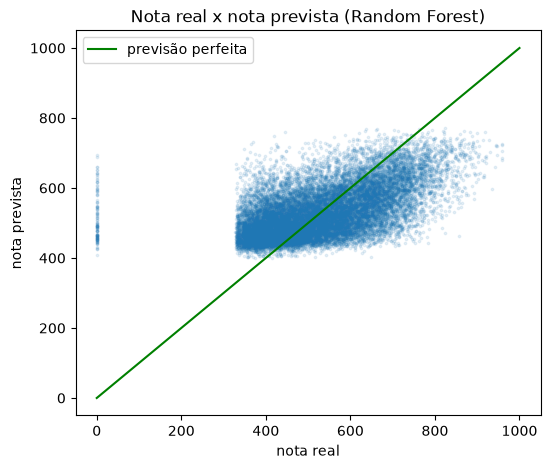

In [90]:
real_x_previsto(floresta, "Random Forest")

### Passo 4: salvar em `models/`

In [91]:
joblib.dump(floresta, f"../models/random_forest_{NOME}.joblib")

['../models/random_forest_dataset_1_fundido.joblib']

## 9. Gradient Boosting

**O que é:** `GradientBoostingRegressor` ou `HistGradientBoostingRegressor`: árvores pequenas treinadas em sequência, cada uma corrigindo o erro das anteriores.

**Pontos de atenção:** O `HistGradientBoostingRegressor` é bem mais rápido em bases grandes. Se houver parada antecipada, usar uma parcela interna do treino da dobra, nunca o teste. Hiperparâmetros: `learning_rate`, `max_iter`, `max_depth`, `min_samples_leaf`.

### Passo 1: treinar e medir

No boosting as árvores são treinadas **em sequência**: cada nova árvore tenta corrigir o erro que as anteriores deixaram. Usamos o `HistGradientBoostingRegressor`, que agrupa cada feature em faixas e por isso é muito mais rápido em bases grandes.

Configuração inicial: `learning_rate=0.1` (quanto cada árvore corrige), até `max_iter=300` árvores de no máximo 31 folhas, `min_samples_leaf=200`. Com `early_stopping=True` ele separa 10% do treino de cada dobra e para quando o erro nesses 10% para de melhorar (o teste nunca entra).

In [92]:
from sklearn.ensemble import HistGradientBoostingRegressor

gradient_boosting = HistGradientBoostingRegressor(learning_rate=0.1, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
                                                  early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                                  random_state=42)
avaliar(gradient_boosting, "Gradient Boosting")

,média,desvio
RMSE,107.770,0.226
MAE,83.825,0.120
R2,0.330,0.002
MSE,11614.509,48.754
tempo_s,132.725,66.696


### Passo 2: as features que mais influenciaram

O `HistGradientBoostingRegressor` não tem `feature_importances_`, então usamos a importância por permutação.

TP_COR_RACA    0.96
Q024           1.72
TP_SEXO        2.05
TP_LINGUA      2.11
FUSAO_1        3.95
Q006           6.03


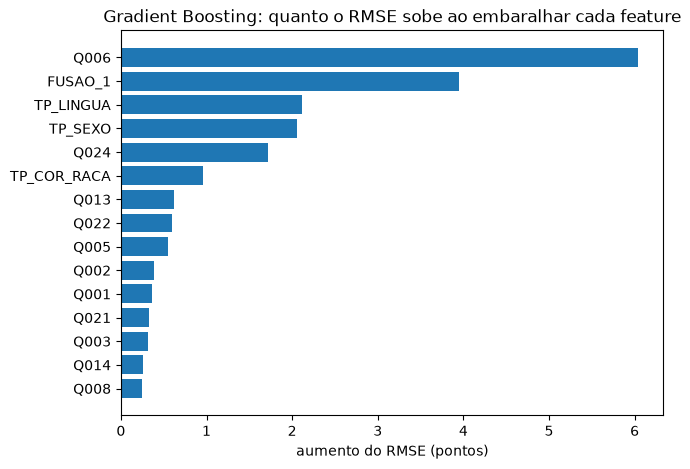

In [93]:
imp_gb = importancia_por_permutacao(gradient_boosting)
print(imp_gb.tail(6).round(2).to_string())
grafico_importancia(imp_gb, "Gradient Boosting: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista

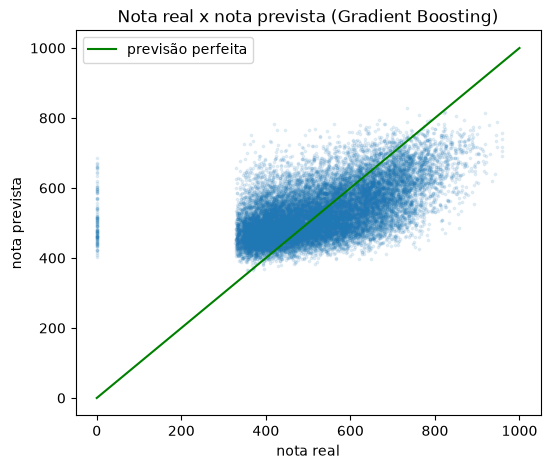

In [94]:
real_x_previsto(gradient_boosting, "Gradient Boosting")

### Passo 4: salvar em `models/`

In [95]:
gradient_boosting.fit(X, y)
joblib.dump(gradient_boosting, f"../models/gradient_boosting_{NOME}.joblib")

['../models/gradient_boosting_dataset_1_fundido.joblib']

## 10. Stacking

**O que é:** `StackingRegressor`: junta as previsões de vários modelos (por exemplo Ridge, Random Forest e Gradient Boosting) e um modelo final aprende a combiná-las.

**Pontos de atenção:** Só faz sentido depois dos outros modelos treinados e comparados. Treina os modelos base várias vezes (validação cruzada interna), então é o mais caro. Escolhas: quais modelos entram, o modelo final (por exemplo `Ridge`) e o `cv` interno.

### Passo 1: treinar e medir

O stacking treina vários modelos diferentes (os "de base") e um modelo final, um Ridge, aprende **como combinar as previsões deles**. Para o modelo final não aprender em cima de previsões que os modelos de base fizeram sobre o próprio treino, as previsões usadas por ele vêm de uma validação cruzada interna (`cv`, 3 dobras) dentro do treino de cada dobra.

Modelos de base: regressão linear com Ridge, árvore de decisão e Gradient Boosting. É o mais caro: cada modelo de base é treinado várias vezes.

In [96]:
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import KFold

stacking = StackingRegressor(
    estimators=[("ridge", make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
                ("arvore", DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=42)),
                ("gradient_boosting", HistGradientBoostingRegressor(learning_rate=0.1, max_iter=300, max_leaf_nodes=31,
                                                                    min_samples_leaf=200, early_stopping=True, random_state=42))],
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(n_splits=3, shuffle=True, random_state=42))
avaliar(stacking, "Stacking")

,média,desvio
RMSE,107.763,0.226
MAE,83.804,0.121
R2,0.330,0.002
MSE,11612.890,48.745
tempo_s,629.819,559.908


### Passo 2: as features que mais influenciaram

Importância por permutação. Além disso, os **pesos que o modelo final deu a cada modelo de base** dizem em quem o stacking mais confia.

Pesos do modelo final para cada modelo de base:
ridge               -0.014
arvore              -0.049
gradient_boosting    1.060
TP_COR_RACA    0.96
Q024           1.72
TP_SEXO        2.06
TP_LINGUA      2.09
FUSAO_1        4.02
Q006           5.96


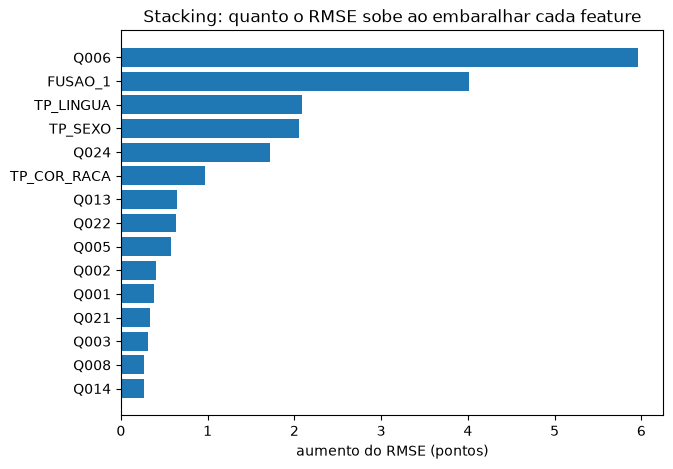

In [97]:
stacking.fit(X, y)
print("Pesos do modelo final para cada modelo de base:")
print(pd.Series(stacking.final_estimator_.coef_, index=[n for n, _ in stacking.estimators]).round(3).to_string())

imp_stack = importancia_por_permutacao(stacking)
print(imp_stack.tail(6).round(2).to_string())
grafico_importancia(imp_stack, "Stacking: quanto o RMSE sobe ao embaralhar cada feature", "aumento do RMSE (pontos)")

### Passo 3: nota real × nota prevista

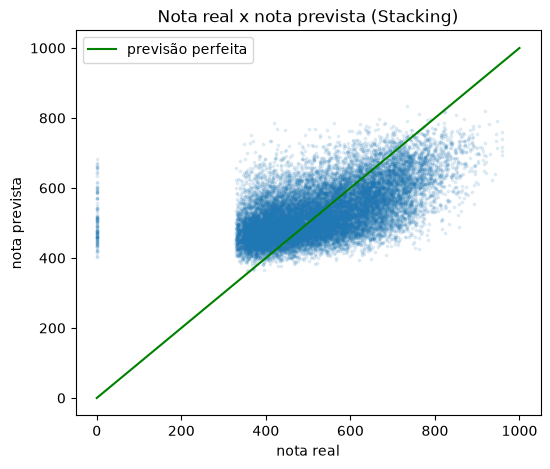

In [98]:
real_x_previsto(stacking, "Stacking")

### Passo 4: salvar em `models/`

In [99]:
joblib.dump(stacking, f"../models/stacking_{NOME}.joblib")

['../models/stacking_dataset_1_fundido.joblib']

## 11. Comparação dos modelos

Uma tabela com RMSE, MAE, R² (média ± desvio), tempo e dataset de cada modelo, para escolher os três melhores regressores distintos.

### Passo 1: tabela

Todos os modelos, no mesmo dataset e nas mesmas 3 dobras, ordenados pelo RMSE médio (menor é melhor). `RMSE_desvio` é o desvio do RMSE entre as dobras: se a diferença entre dois modelos for menor que ele, não dá para dizer que um é melhor. `tempo_s` é o tempo de treino e previsão em uma dobra.

In [100]:
comparacao = pd.DataFrame({nome: r["média"] for nome, r in resultados.items()}).T
comparacao["RMSE_desvio"] = [resultados[nome].loc["RMSE", "desvio"] for nome in comparacao.index]
comparacao = comparacao.sort_values("RMSE")[["RMSE", "RMSE_desvio", "MAE", "R2", "MSE", "tempo_s"]]
comparacao["ganho_vs_baseline_%"] = (1 - comparacao["RMSE"] / comparacao.loc["Baseline", "RMSE"]) * 100
comparacao.round(3)

,RMSE,RMSE_desvio,MAE,R2,MSE,tempo_s,ganho_vs_baseline_%
Stacking,107.763,0.226,83.804,0.330,11612.890,629.819,18.134
Gradient Boosting,107.770,0.226,83.825,0.330,11614.509,132.725,18.129
Random Forest,109.422,0.195,85.494,0.309,11973.271,103.420,16.874
Pasting,110.012,0.208,85.996,0.302,12102.686,19.845,16.426
Bagging,110.014,0.207,85.991,0.302,12103.132,24.135,16.424
Árvore de decisão,110.551,0.190,86.381,0.295,12221.635,2.973,16.016
Ridge,111.153,0.178,86.960,0.287,12354.950,0.300,15.559
Regressão linear,111.153,0.178,86.960,0.287,12354.950,0.678,15.559
SVR linear,111.153,0.178,86.961,0.287,12354.951,1.942,15.559
KNN,111.575,0.184,87.180,0.282,12449.014,476.276,15.239


### Passo 2: gráficos

À esquerda, o RMSE de cada modelo com o desvio entre as dobras (barra de erro). À direita, o tempo: modelos parecidos em erro podem ter custos bem diferentes.

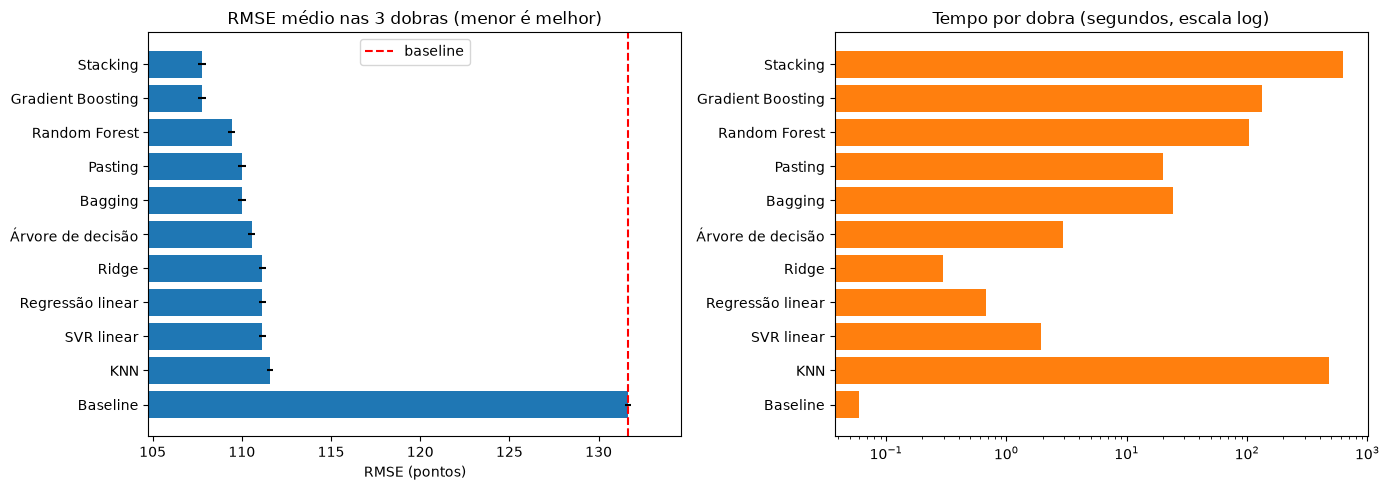

In [101]:
ordem = comparacao.sort_values("RMSE", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(ordem.index, ordem["RMSE"], xerr=ordem["RMSE_desvio"], color="tab:blue")
ax[0].axvline(comparacao.loc["Baseline", "RMSE"], color="red", ls="--", label="baseline")
ax[0].set_xlim(ordem["RMSE"].min() - 3, ordem["RMSE"].max() + 3)
ax[0].set_title("RMSE médio nas 3 dobras (menor é melhor)")
ax[0].set_xlabel("RMSE (pontos)")
ax[0].legend()
ax[1].barh(ordem.index, ordem["tempo_s"], color="tab:orange")
ax[1].set_xscale("log")
ax[1].set_title("Tempo por dobra (segundos, escala log)")
plt.tight_layout()
plt.show()

### Passo 3: os 3 melhores regressores distintos

O PDF pede os **3 melhores regressores distintos, sem contar o baseline**, para a busca de hiperparâmetros. Regressão linear e Ridge são da mesma família, então contam como um só (o melhor dos dois). Idem para bagging e pasting, que são variações do mesmo método.

In [102]:
familia = {"Regressão linear": "Linear", "Ridge": "Linear", "Árvore de decisão": "Árvore", "KNN": "KNN", "SVR linear": "SVR",
           "Bagging": "Bagging/Pasting", "Pasting": "Bagging/Pasting", "Random Forest": "Random Forest",
           "Gradient Boosting": "Gradient Boosting", "Stacking": "Stacking"}
sem_baseline = comparacao.drop("Baseline")
melhores = sem_baseline.assign(familia=sem_baseline.index.map(familia)).drop_duplicates("familia").head(3)
print("Os 3 melhores regressores distintos (pelo RMSE médio):")
melhores[["familia", "RMSE", "RMSE_desvio", "tempo_s"]].round(3)

Os 3 melhores regressores distintos (pelo RMSE médio):


,familia,RMSE,RMSE_desvio,tempo_s
Stacking,Stacking,107.763,0.226,629.819
Gradient Boosting,Gradient Boosting,107.770,0.226,132.725
Random Forest,Random Forest,109.422,0.195,103.420


## 12. Comparação dos datasets

Um modelo por dataset, para ver qual conjunto de features ajuda mais. Treinamos nos 8 datasets (nas mesmas dobras):

- a **regressão linear**, como referência rápida;
- o **melhor modelo da seção 11 que não seja muito lento** (menos de 400 s por dobra), que também é salvo em `models/`.

Mudar de dataset muda só as colunas: as linhas e as dobras são as mesmas.

In [103]:
todos = {"Regressão linear": regressao_linear, "Ridge": ridge, "Árvore de decisão": arvore, "KNN": knn, "SVR linear": svr,
         "Bagging": bagging, "Pasting": pasting, "Random Forest": floresta, "Gradient Boosting": gradient_boosting,
         "Stacking": stacking}
rapidos = comparacao.drop("Baseline")[comparacao.drop("Baseline")["tempo_s"] < 400]
melhor = rapidos.index[0]
print(f"Melhor modelo rápido da seção 11: {melhor} (RMSE {rapidos.loc[melhor, 'RMSE']:.3f}, {rapidos.loc[melhor, 'tempo_s']:.0f} s por dobra)")

por_dataset = []
for nome in DATASETS:
    X, y = carregar(nome)                      # a função avaliar usa o X e o y atuais
    for modelo_nome in dict.fromkeys(["Regressão linear", melhor]):
        r = avaliar(todos[modelo_nome])
        por_dataset.append({"dataset": nome, "features": X.shape[1], "modelo": modelo_nome,
                            "RMSE": r.loc["RMSE", "média"], "RMSE_desvio": r.loc["RMSE", "desvio"],
                            "MAE": r.loc["MAE", "média"], "R2": r.loc["R2", "média"], "tempo_s": r.loc["tempo_s", "média"]})
        if modelo_nome == melhor:              # salva o melhor modelo treinado nos 80% de cada dataset
            joblib.dump(clone(todos[modelo_nome]).fit(X, y), f"../models/{melhor.lower().replace(' ', '_')}_{nome}.joblib")
    print(f"{nome:<32} ok")
X, y = carregar(NOME)                          # volta ao dataset de trabalho

tabela_datasets = pd.DataFrame(por_dataset)
tabela_datasets.round(3)

Melhor modelo rápido da seção 11: Gradient Boosting (RMSE 107.770, 133 s por dobra)
dataset_1_fundido                ok
dataset_1_features               ok
dataset_2_escola                 ok
dataset_2_features_escola        ok
dataset_3_sem_escola             ok
dataset_3_sem_escola_features    ok
dataset_3_escola                 ok
dataset_3_escola_features        ok


,dataset,features,modelo,RMSE,RMSE_desvio,MAE,R2,tempo_s
0,dataset_1_fundido,30,Regressão linear,111.153,0.178,86.960,0.287,1.688
1,dataset_1_fundido,30,Gradient Boosting,107.770,0.226,83.825,0.330,72.534
2,dataset_1_features,33,Regressão linear,111.146,0.178,86.951,0.287,1.785
3,dataset_1_features,33,Gradient Boosting,107.759,0.239,83.812,0.330,70.102
4,dataset_2_escola,34,Regressão linear,110.747,0.183,86.596,0.292,1.748
5,dataset_2_escola,34,Gradient Boosting,107.261,0.202,83.364,0.336,61.534
6,dataset_2_features_escola,37,Regressão linear,110.742,0.183,86.590,0.292,2.253
7,dataset_2_features_escola,37,Gradient Boosting,107.255,0.194,83.358,0.336,61.999
8,dataset_3_sem_escola,38,Regressão linear,110.752,0.185,86.570,0.292,2.401
9,dataset_3_sem_escola,38,Gradient Boosting,107.551,0.211,83.610,0.332,56.931


RMSE médio nas 3 dobras (baseline = 131.634 em todos):
modelo                         Gradient Boosting  Regressão linear
dataset                                                           
dataset_1_fundido                        107.770           111.153
dataset_1_features                       107.759           111.146
dataset_2_escola                         107.261           110.747
dataset_2_features_escola                107.255           110.742
dataset_3_sem_escola                     107.551           110.752
dataset_3_sem_escola_features            107.540           110.744
dataset_3_escola                         107.056           110.384
dataset_3_escola_features                107.048           110.378


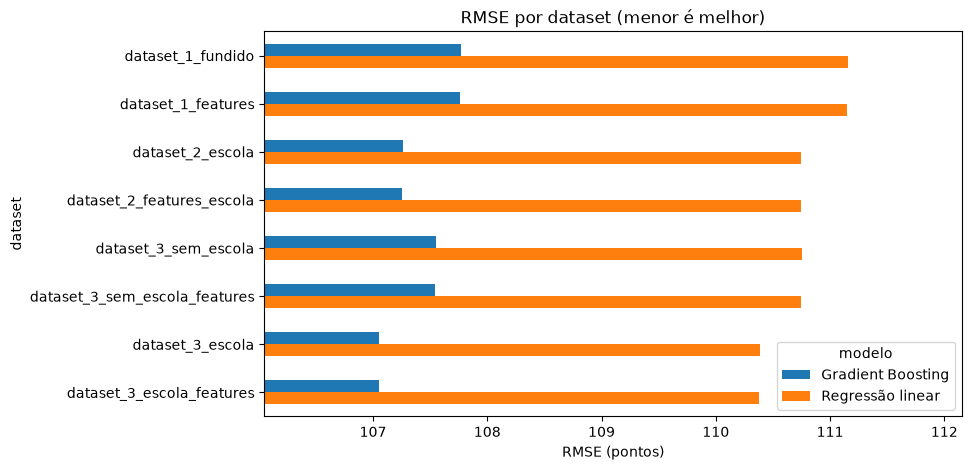

In [104]:
pivo = tabela_datasets.pivot(index="dataset", columns="modelo", values="RMSE").loc[DATASETS]
print("RMSE médio nas 3 dobras (baseline = %.3f em todos):" % comparacao.loc["Baseline", "RMSE"])
print(pivo.round(3).to_string())

pivo.plot.barh(figsize=(9, 5), title="RMSE por dataset (menor é melhor)")
plt.xlim(pivo.min().min() - 1, pivo.max().max() + 1)
plt.xlabel("RMSE (pontos)")
plt.gca().invert_yaxis()
plt.show()